## Classification Project Machine Learning 2

#### Katarzyna Pełka (432453)
#### Izabela Kosiec (441755)

### Introduction

In recent years, wellbeing and lifestyle datasets have become increasingly popular in data science research, as they capture complex behavioural, health-related, and social patterns at the individual level. Understanding whether such patterns differ systematically across demographic groups can provide insight into both the predictive power and the limitations of behavioural data.

The goal of this project is to investigate whether lifestyle and wellbeing indicators are sufficient to predict an individual's gender. While gender is a sensitive attribute and not directly observable from behaviour alone, this task provides an interesting and challenging classification problem with a weak predictive signal. From a methodological perspective, it allows for the evaluation of different machine learning models under realistic conditions, including noisy features, overlapping distributions, and moderate class imbalance.

This topic was chosen to move beyond trivial classification tasks and to assess how modern machine learning models behave when the underlying differences between classes are subtle rather than clearly separable.



### Data description

The dataset used in this project comes from Kaggle and contains self-reported wellbeing and lifestyle data for nearly 16,000 individuals. The variables describe daily habits, health-related behaviours, social interactions, stress levels, physical activity, and work–life balance.

The target variable is `gender`, with two classes: Female and Male. The feature set consists of both numeric variables (mostly ordinal scales ranging from 0–10 or 1–10) and categorical variables such as age group and stress level categories.

The dataset is well-suited for a classification task, but it also presents several challenges: the majority of features are subjective, distributions overlap strongly across genders, and the target variable is moderately imbalanced in favour of females. These characteristics make the problem non-trivial and realistic from a machine learning perspective.


In [2]:
# imports
import os
import random

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed in this environment.")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Plot style 
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [3]:
# Loading dataset
data_path = "Wellbeing_and_lifestyle_data_Kaggle.csv"
df = pd.read_csv(data_path)

print("Shape of the raw dataset:", df.shape)
df.head()


Shape of the raw dataset: (15972, 24)


,Timestamp,FRUITS_VEGGIES,DAILY_STRESS,PLACES_VISITED,CORE_CIRCLE,SUPPORTING_OTHERS,SOCIAL_NETWORK,ACHIEVEMENT,DONATION,BMI_RANGE,...,SLEEP_HOURS,LOST_VACATION,DAILY_SHOUTING,SUFFICIENT_INCOME,PERSONAL_AWARDS,TIME_FOR_PASSION,WEEKLY_MEDITATION,AGE,GENDER,WORK_LIFE_BALANCE_SCORE
0,7/7/15,3,2,2,5,0,5,2,0,1,...,7,5,5,1,4,0,5,36 to 50,Female,609.5
1,7/7/15,2,3,4,3,8,10,5,2,2,...,8,2,2,2,3,2,6,36 to 50,Female,655.6
2,7/7/15,2,3,3,4,4,10,3,2,2,...,8,10,2,2,4,8,3,36 to 50,Female,631.6
3,7/7/15,3,3,10,3,10,7,2,5,2,...,5,7,5,1,5,2,0,51 or more,Female,622.7
4,7/7/15,5,1,3,3,10,4,2,4,2,...,7,0,0,2,8,1,5,51 or more,Female,663.9


The dataset `Wellbeing_and_lifestyle_data_Kaggle.csv` contains 15 972 observations and 24 columns
describing wellbeing, lifestyle and social variables.

Examples of variables:

- **FRUITS_VEGGIES** – daily portions of fruits and vegetables  
- **DAILY_STRESS** – self-reported daily stress level (1–5)  
- **PLACES_VISITED** – number of places visited  
- **CORE_CIRCLE** – size of close social circle  
- **SUPPORTING_OTHERS, SOCIAL_NETWORK, ACHIEVEMENT, DONATION** – social and altruistic behaviours  
- **BMI_RANGE, DAILY_STEPS, SLEEP_HOURS** – physical health and activity metrics  
- **LIVE_VISION, TIME_FOR_PASSION, WEEKLY_MEDITATION** – long-term life and mental wellbeing indicators  
- **LOST_VACATION, DAILY_SHOUTING** – signals of work stress and conflict  
- **SUFFICIENT_INCOME, PERSONAL_AWARDS** – financial and professional situation  
- **AGE** – age group (categorical)  
- **WORK_LIFE_BALANCE_SCORE** – continuous score of work–life balance  
- **GENDER** – target: Female / Male  



In [5]:
# Basic info about columns and types
print("Dataset info:")
print(df.info())

# Checking missing values
print("\nMissing values per column:")
print(df.isna().sum())


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15972 entries, 0 to 15971
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Timestamp                15972 non-null  object 
 1   FRUITS_VEGGIES           15972 non-null  int64  
 2   DAILY_STRESS             15972 non-null  object 
 3   PLACES_VISITED           15972 non-null  int64  
 4   CORE_CIRCLE              15972 non-null  int64  
 5   SUPPORTING_OTHERS        15972 non-null  int64  
 6   SOCIAL_NETWORK           15972 non-null  int64  
 7   ACHIEVEMENT              15972 non-null  int64  
 8   DONATION                 15972 non-null  int64  
 9   BMI_RANGE                15972 non-null  int64  
 10  TODO_COMPLETED           15972 non-null  int64  
 11  FLOW                     15972 non-null  int64  
 12  DAILY_STEPS              15972 non-null  int64  
 13  LIVE_VISION              15972 non-null  int64  
 14  SLEEP_HO

In [6]:
# numerical and categorical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

categorical_cols = categorical_cols.drop("Timestamp")

print("Numeric columns ({}):".format(len(numeric_cols)))
print(list(numeric_cols))

print("\nCategorical columns ({}):".format(len(categorical_cols)))
print(list(categorical_cols))


Numeric columns (20):
['FRUITS_VEGGIES', 'PLACES_VISITED', 'CORE_CIRCLE', 'SUPPORTING_OTHERS', 'SOCIAL_NETWORK', 'ACHIEVEMENT', 'DONATION', 'BMI_RANGE', 'TODO_COMPLETED', 'FLOW', 'DAILY_STEPS', 'LIVE_VISION', 'SLEEP_HOURS', 'LOST_VACATION', 'DAILY_SHOUTING', 'SUFFICIENT_INCOME', 'PERSONAL_AWARDS', 'TIME_FOR_PASSION', 'WEEKLY_MEDITATION', 'WORK_LIFE_BALANCE_SCORE']

Categorical columns (3):
['DAILY_STRESS', 'AGE', 'GENDER']


In [7]:
# Descriptive statistics for numeric columns
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
FRUITS_VEGGIES,15972.0,2.922677,1.442694,0.0,2.0,3.0,4.0,5.0
PLACES_VISITED,15972.0,5.232970,3.311912,0.0,2.0,5.0,8.0,10.0
CORE_CIRCLE,15972.0,5.508077,2.840334,0.0,3.0,5.0,8.0,10.0
SUPPORTING_OTHERS,15972.0,5.616454,3.242021,0.0,3.0,5.0,10.0,10.0
SOCIAL_NETWORK,15972.0,6.474267,3.086672,0.0,4.0,6.0,10.0,10.0
ACHIEVEMENT,15972.0,4.000751,2.755837,0.0,2.0,3.0,6.0,10.0
DONATION,15972.0,2.715314,1.851586,0.0,1.0,3.0,5.0,5.0
BMI_RANGE,15972.0,1.410656,0.491968,1.0,1.0,1.0,2.0,2.0
TODO_COMPLETED,15972.0,5.745993,2.624097,0.0,4.0,6.0,8.0,10.0
FLOW,15972.0,3.194778,2.357518,0.0,1.0,3.0,5.0,10.0


Most numeric variables are measured on bounded ordinal scales (typically 0–10 or 1–10), which limits the presence of extreme outliers and results in distributions centered around mid-range values.  
In contrast, `WORK_LIFE_BALANCE_SCORE` has a much wider range and higher variance, indicating that it represents a more granular composite measure rather than a simple ordinal scale.


In [9]:
# value counts for categorical columns
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].value_counts())



Column: DAILY_STRESS
DAILY_STRESS
3         4398
2         3407
4         2960
1         2478
5         2052
0          676
1/1/00       1
Name: count, dtype: int64

Column: AGE
AGE
21 to 35        6108
36 to 50        4655
51 or more      3390
Less than 20    1819
Name: count, dtype: int64

Column: GENDER
GENDER
Female    9858
Male      6114
Name: count, dtype: int64


In [43]:
# Remove invalid DAILY_STRESS value identified during data inspection
df = df[df["DAILY_STRESS"] != "1/1/00"]
print(df["DAILY_STRESS"].value_counts())


DAILY_STRESS
3    4398
2    3407
4    2960
1    2478
5    2052
0     676
Name: count, dtype: int64


The categorical variables show reasonably balanced distributions, with most respondents reporting moderate levels of daily stress and belonging primarily to the 21–35 and 36–50 age groups.  
The target variable (`GENDER`) is moderately imbalanced in favor of females, which motivated the use of class weighting in the models.

In [46]:
df = df.copy()
df.rename(columns={"GENDER": "gender"}, inplace=True)

# Target distribution
print("Gender distribution (counts):")
print(df["gender"].value_counts())

print("\nGender distribution (relative):")
print(df["gender"].value_counts(normalize=True))

# Baseline accuracy if we always predict the majority class
majority_class = df["gender"].value_counts().idxmax()
baseline_acc = df["gender"].value_counts().max() / len(df)
print("\nMajority class:", majority_class)


Gender distribution (counts):
gender
Female    9858
Male      6113
Name: count, dtype: int64

Gender distribution (relative):
gender
Female    0.617244
Male      0.382756
Name: proportion, dtype: float64

Majority class: Female


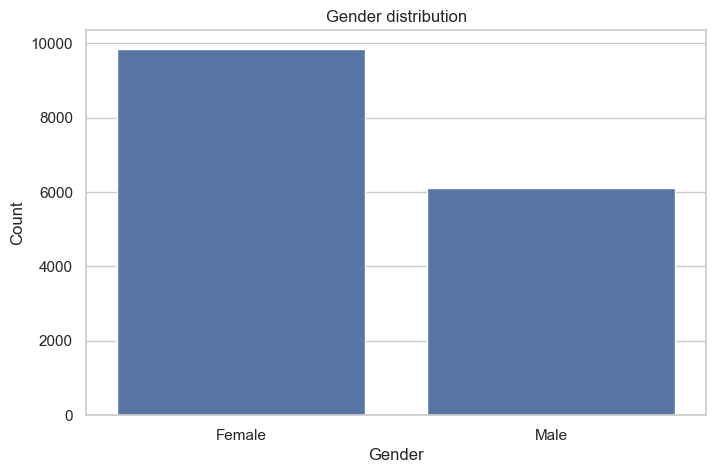

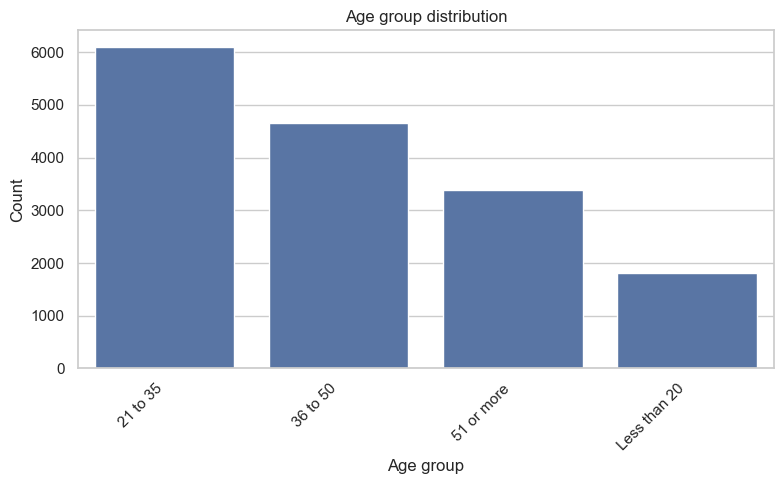

In [48]:
# Gender distribution plot
sns.countplot(x="gender", data=df)
plt.title("Gender distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

# Age distribution
sns.countplot(x="AGE", data=df, order=df["AGE"].value_counts().index)
plt.title("Age group distribution")
plt.xlabel("Age group")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


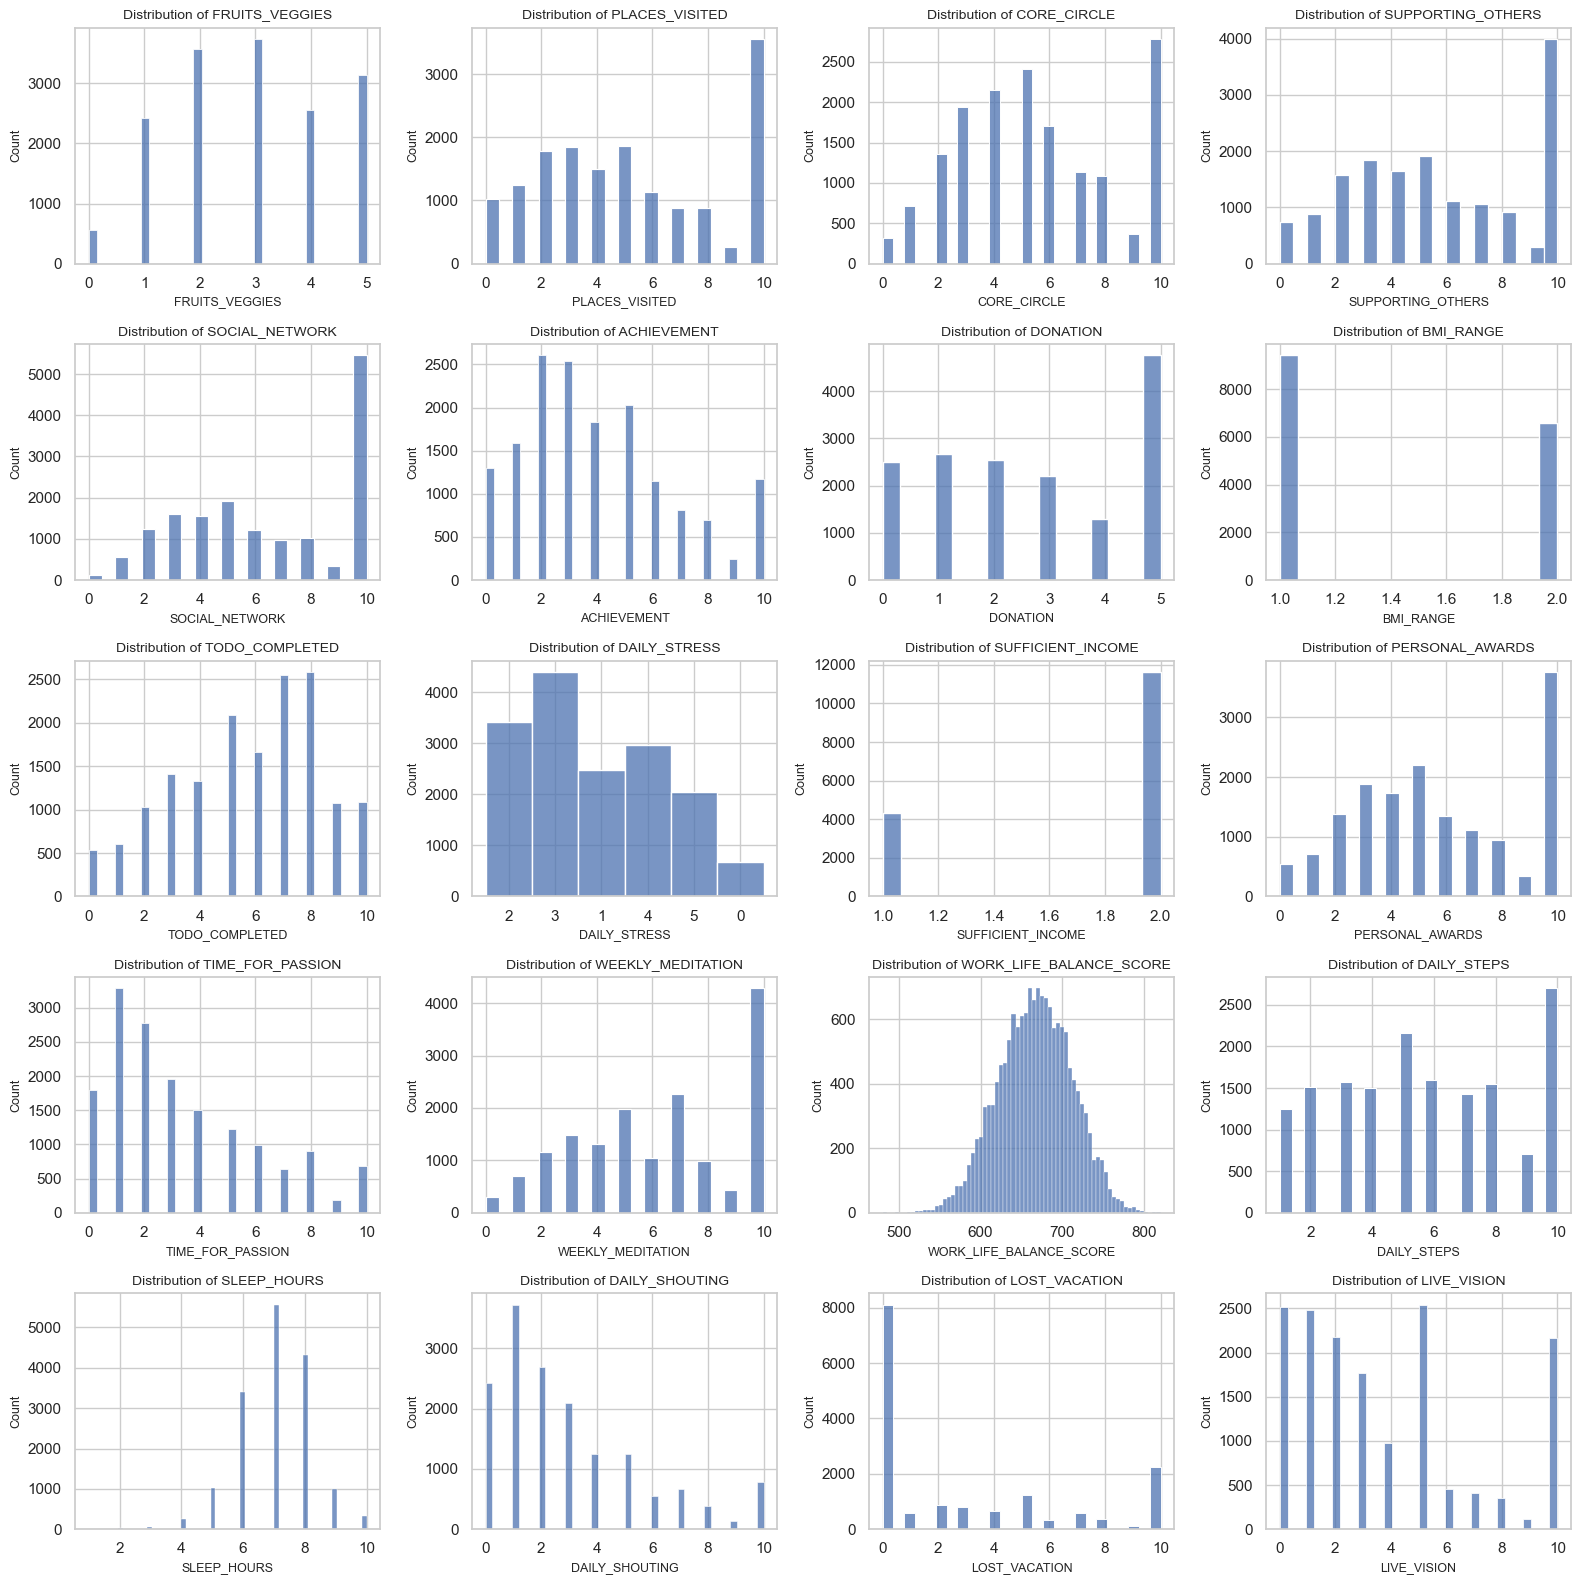

In [49]:
# Histograms for numeric variables
num_to_plot = [
    'FRUITS_VEGGIES', 'PLACES_VISITED', 'CORE_CIRCLE', 'SUPPORTING_OTHERS',
    'SOCIAL_NETWORK', 'ACHIEVEMENT', 'DONATION', 'BMI_RANGE',
    'TODO_COMPLETED', 'DAILY_STRESS', 'SUFFICIENT_INCOME', 'PERSONAL_AWARDS',
    'TIME_FOR_PASSION', 'WEEKLY_MEDITATION', 'WORK_LIFE_BALANCE_SCORE',
    'DAILY_STEPS', 'SLEEP_HOURS', 'DAILY_SHOUTING', 'LOST_VACATION',
    'LIVE_VISION'
]

n_plots = len(num_to_plot)
n_cols = 4
n_rows = int(np.ceil(n_plots / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 16))  
axes = axes.flatten()  

for ax, col in zip(axes, num_to_plot):
    sns.histplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}", fontsize=10)
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel("Count", fontsize=9)

for j in range(len(num_to_plot), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


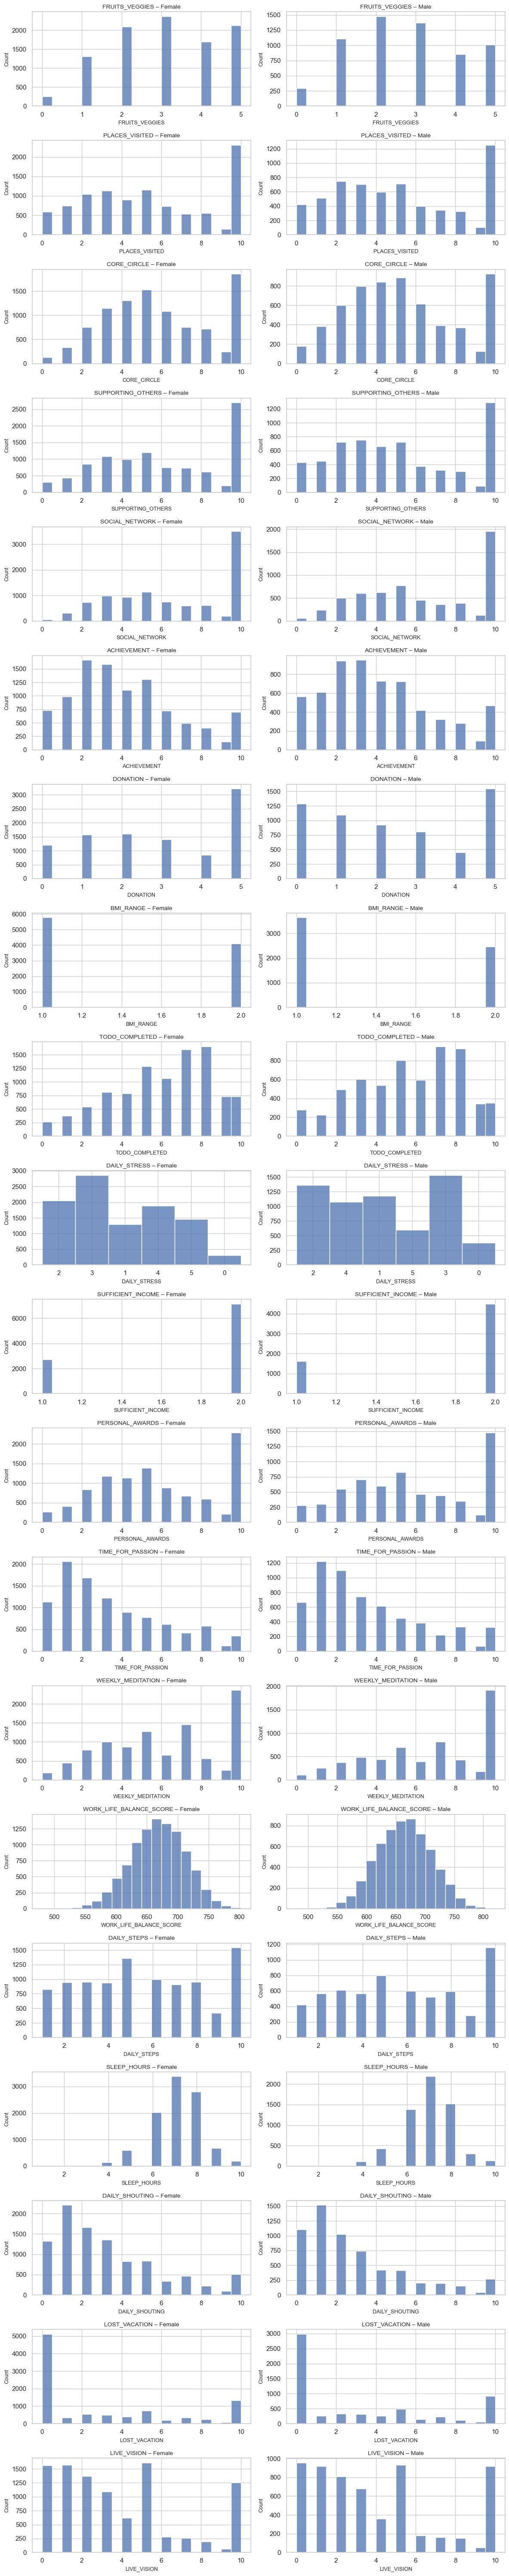

In [50]:
# numeric variables
num_to_plot = [
    'FRUITS_VEGGIES', 'PLACES_VISITED', 'CORE_CIRCLE', 'SUPPORTING_OTHERS',
    'SOCIAL_NETWORK', 'ACHIEVEMENT', 'DONATION', 'BMI_RANGE',
    'TODO_COMPLETED', 'DAILY_STRESS', 'SUFFICIENT_INCOME', 'PERSONAL_AWARDS',
    'TIME_FOR_PASSION', 'WEEKLY_MEDITATION', 'WORK_LIFE_BALANCE_SCORE',
    'DAILY_STEPS', 'SLEEP_HOURS', 'DAILY_SHOUTING', 'LOST_VACATION',
    'LIVE_VISION'
]

genders = ["Female", "Male"]

n_rows = len(num_to_plot)
n_cols = 2 

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(12, 3 * n_rows),
    sharex=False,  
    sharey=False   
)


if n_rows == 1:
    axes = np.array([axes])

for i, col in enumerate(num_to_plot):
    for j, gender in enumerate(genders):
        ax = axes[i, j]
        # Filter data for a given gender
        df_gender = df[df["gender"] == gender]

        sns.histplot(data=df_gender, x=col, bins=20, ax=ax)

        ax.set_title(f"{col} – {gender}", fontsize=10)
        ax.set_xlabel(col, fontsize=9)
        ax.set_ylabel("Count", fontsize=9)

plt.tight_layout()
plt.show()


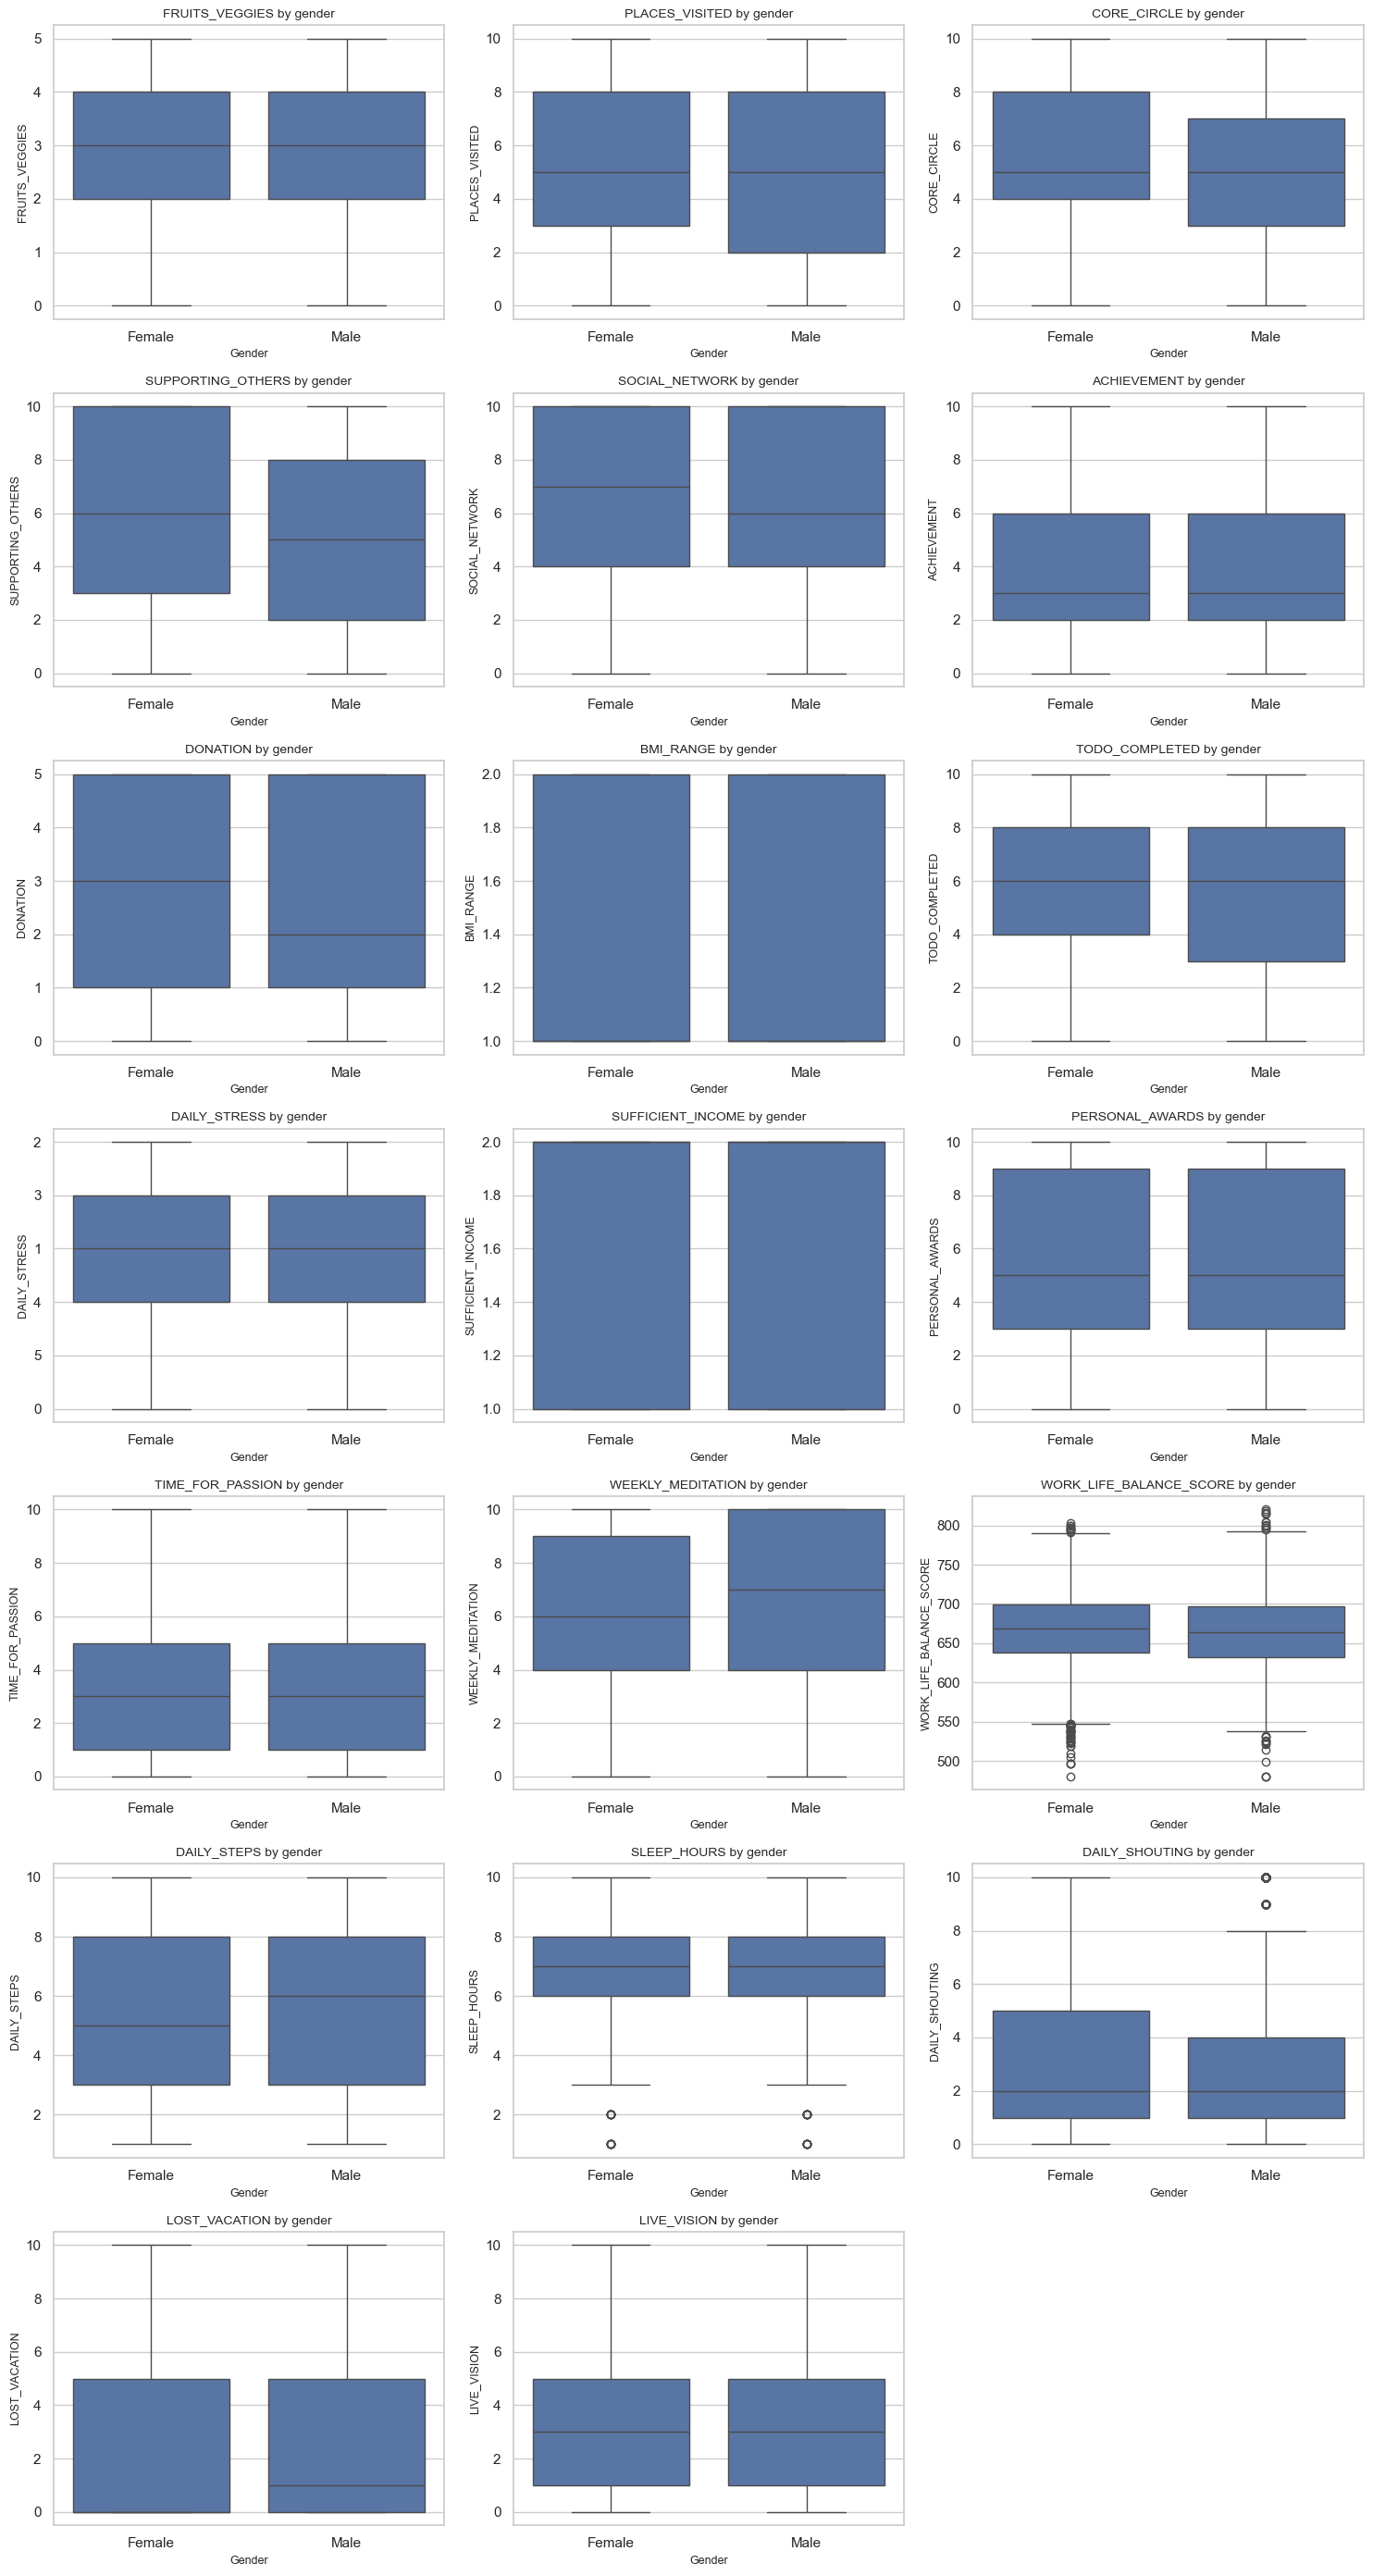

In [51]:
# Boxplots for numeric features by gender

num_features = num_to_plot  
n_cols = 3
n_rows = int(np.ceil(len(num_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows)  
)

axes = axes.flatten()

for ax, col in zip(axes, num_features):
    sns.boxplot(data=df, x="gender", y=col, ax=ax)
    ax.set_title(f"{col} by gender", fontsize=10)
    ax.set_xlabel("Gender", fontsize=9)
    ax.set_ylabel(col, fontsize=9)


for i in range(len(num_features), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()



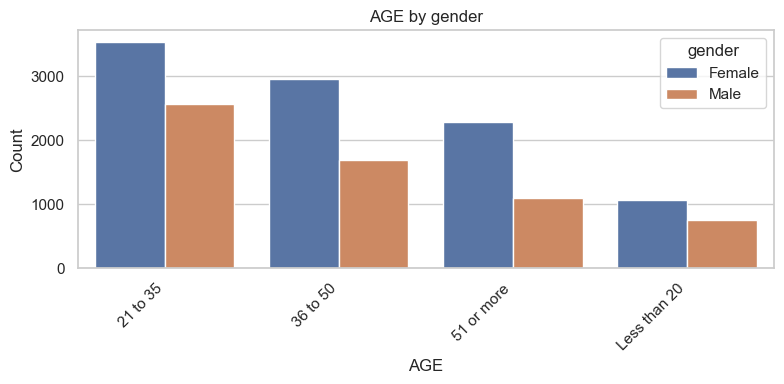

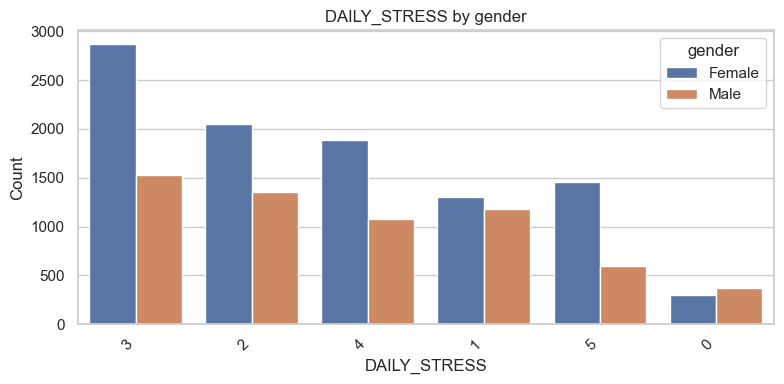

In [52]:
# Categorical features vs gender
cat_to_plot = ["AGE", "DAILY_STRESS"]

for col in cat_to_plot:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue="gender",
                  order=df[col].value_counts().index)
    plt.title(f"{col} by gender")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


The distributions of most variables are highly similar between males and females, with substantial overlap across both central tendencies and dispersion measures. As a result, the available features provide limited discriminatory signal, which makes it challenging for the models to achieve prediction performance substantially above a simple baseline.

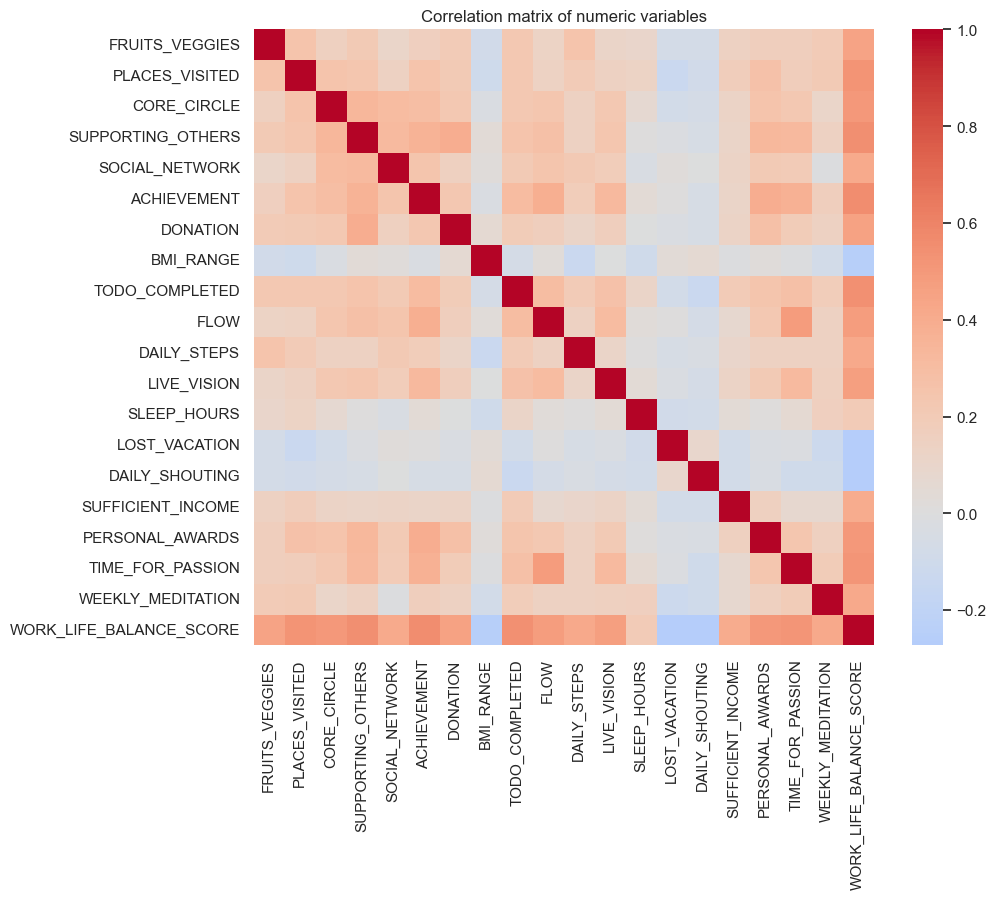

In [55]:
# Correlation matrix for numeric variables
plt.figure(figsize=(10, 8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation matrix of numeric variables")
plt.show()


In [119]:
# Encode gender to numeric to compute correlation with features
gender_numeric = df["gender"].map({"Female": 0, "Male": 1})

corr_with_gender = df[numeric_cols].corrwith(gender_numeric).sort_values(ascending=False)

print("Correlation of numeric features with gender (Male=1, Female=0):")
corr_with_gender


Correlation of numeric features with gender (Male=1, Female=0):


WEEKLY_MEDITATION          0.087545
DAILY_STEPS                0.037650
LIVE_VISION                0.030817
LOST_VACATION              0.025780
TIME_FOR_PASSION           0.016590
SUFFICIENT_INCOME          0.010419
ACHIEVEMENT                0.000598
BMI_RANGE                 -0.010766
PERSONAL_AWARDS           -0.013848
FLOW                      -0.017370
WORK_LIFE_BALANCE_SCORE   -0.039911
SOCIAL_NETWORK            -0.041020
PLACES_VISITED            -0.042662
SLEEP_HOURS               -0.058400
DAILY_SHOUTING            -0.064605
TODO_COMPLETED            -0.081400
CORE_CIRCLE               -0.096481
FRUITS_VEGGIES            -0.110211
DONATION                  -0.118754
SUPPORTING_OTHERS         -0.131476
dtype: float64

### Exploratory Data Analysis

The exploratory analysis revealed that most numeric variables follow bounded ordinal distributions with limited extreme values. Visualisations such as histograms and boxplots showed substantial overlap between males and females across nearly all features, with only minor differences in medians and spreads.

Categorical variables exhibited reasonable distributions, with most respondents reporting moderate stress levels and belonging primarily to the 21–35 and 36–50 age groups. The gender variable showed moderate imbalance, motivating the later use of class weighting.

Overall, the EDA suggested that lifestyle and wellbeing variables provide only weak discriminatory power for gender classification, which informed both model choice and evaluation strategy in later stages.


### Data preprocessing

Prior to model training, several preprocessing steps were applied to ensure data quality and reproducibility. Numeric and categorical variables were identified explicitly and handled separately.

Categorical variables were encoded using one-hot encoding, while avoiding high-cardinality columns (e.g. timestamps) that could lead to an unnecessary explosion of feature space. Numeric features were standardised where required, particularly for Logistic Regression, to ensure comparable feature scales.

No rows were removed during preprocessing; all transformations preserved the original number of observations. This was verified by checking dataset shapes after each transformation step. These preprocessing decisions were made to balance model performance, interpretability, and computational
efficiency.


In [59]:
#Data preprocessing

data_model = df.copy()

# Dropping Timestamp
if "Timestamp" in data_model.columns:
    data_model.drop(columns=["Timestamp"], inplace=True)

# Target encoding: Female -> 0, Male -> 1
y = data_model["gender"].map({"Female": 0, "Male": 1})

# Drop target from feature set
X = data_model.drop(columns=["gender"])

# One-hot encode categorical variables 
X_encoded = pd.get_dummies(X, drop_first=True)

print("Shape after one-hot encoding:", X_encoded.shape)

# Train-test split with stratification to preserve gender distribution
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Shape after one-hot encoding: (15971, 28)
Train shape: (12776, 28)
Test shape: (3195, 28)


In [72]:
# Standardise features for models sensitive to feature scale (Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [80]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
 
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Some models provide predict_proba, others may not
    if hasattr(model, "predict_proba"):
        y_proba_test = model.predict_proba(X_test)[:, 1]
    else:
        y_proba_test = None

    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)
    test_prec = precision_score(y_test, y_pred_test, zero_division=0)
    test_rec = recall_score(y_test, y_pred_test, zero_division=0)
    test_f1 = f1_score(y_test, y_pred_test, zero_division=0)

    if y_proba_test is not None:
        test_roc_auc = roc_auc_score(y_test, y_proba_test)
    else:
        test_roc_auc = np.nan

    print(f"\n=== {model_name} ===")
    print(f"Train accuracy: {train_acc:.3f}")
    print(f"Test accuracy:  {test_acc:.3f}")
    print(f"Test precision: {test_prec:.3f}")
    print(f"Test recall:    {test_rec:.3f}")
    print(f"Test F1-score:  {test_f1:.3f}")
    print(f"Test ROC-AUC:   {test_roc_auc:.3f}")

    print("\nClassification report on test set:")
    print(classification_report(y_test, y_pred_test, target_names=["Female", "Male"]))

    metrics = {
        "model": model_name,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc,
        "test_precision": test_prec,
        "test_recall": test_rec,
        "test_f1": test_f1,
        "test_roc_auc": test_roc_auc
    }
    return model, metrics


### Models and tuning strategy

Multiple supervised classification models were evaluated, ranging from a simple linear baseline (Logistic Regression) to more complex ensemble methods (Random Forest, Gradient Boosting, and XGBoost). This selection allows for a structured comparison between linear and non-linear approaches.

For each model, a hyperparameter grid was explored using cross-validation, adjusted on the way and limited later in the code so it can run faster. This approach balances model quality and training time. The primary selection metric is the F1-score, complemented by accuracy, precision, recall, and ROC-AUC to provide a comprehensive evaluation.



### Handling class imbalance

Given the moderate imbalance between Female and Male classes, class weighting was introduced where appropriate. Logistic Regression was trained with balanced class weights, which significantly improved recall for the minority class.

For XGBoost, class imbalance was addressed using the `scale_pos_weight` parameter, resulting in a more balanced precision–recall trade-off and the highest overall F1-score in the project. These adjustments improved fairness and reduced systematic bias toward the majority class.


In [84]:
#Logistic Regression
log_param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "solver": ["liblinear", "lbfgs"],
    "penalty": ["l2"],
    "class_weight": [None, "balanced"]
}

log_base = LogisticRegression(max_iter=1000)

log_grid = GridSearchCV(
    estimator=log_base,
    param_grid=log_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

log_grid.fit(X_train_scaled, y_train)

print("Best Logistic Regression parameters:", log_grid.best_params_)
print("Best mean CV F1-score:", log_grid.best_score_)

log_best = log_grid.best_estimator_

log_best, metrics_log = evaluate_model(
    log_best,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    model_name="Logistic Regression (tuned)"
)


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Logistic Regression parameters: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Best mean CV F1-score: 0.5632791584687012

=== Logistic Regression (tuned) ===
Train accuracy: 0.631
Test accuracy:  0.612
Test precision: 0.495
Test recall:    0.599
Test F1-score:  0.542
Test ROC-AUC:   0.661

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.71      0.62      0.66      1972
        Male       0.49      0.60      0.54      1223

    accuracy                           0.61      3195
   macro avg       0.60      0.61      0.60      3195
weighted avg       0.63      0.61      0.62      3195



In [86]:
# Random Forest

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "max_features": ["sqrt", "log2"]
}

rf_base = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_grid = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best mean CV F1-score:", rf_grid.best_score_)

rf_best = rf_grid.best_estimator_

rf_best, metrics_rf = evaluate_model(
    rf_best,
    X_train,
    X_test,
    y_train,
    y_test,
    model_name="Random Forest (tuned)"
)


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Random Forest parameters: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 200}
Best mean CV F1-score: 0.4438839163926937

=== Random Forest (tuned) ===
Train accuracy: 1.000
Test accuracy:  0.685
Test precision: 0.671
Test recall:    0.349
Test F1-score:  0.459
Test ROC-AUC:   0.702

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.69      0.89      0.78      1972
        Male       0.67      0.35      0.46      1223

    accuracy                           0.69      3195
   macro avg       0.68      0.62      0.62      3195
weighted avg       0.68      0.69      0.66      3195



In [87]:
# Gradient Boosting 

gbrt_param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

gbrt_base = GradientBoostingClassifier(random_state=RANDOM_STATE)

gbrt_grid = GridSearchCV(
    estimator=gbrt_base,
    param_grid=gbrt_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

gbrt_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:", gbrt_grid.best_params_)
print("Best mean CV F1-score:", gbrt_grid.best_score_)

gbrt_best = gbrt_grid.best_estimator_

gbrt_best, metrics_gbrt = evaluate_model(
    gbrt_best,
    X_train,
    X_test,
    y_train,
    y_test,
    model_name="Gradient Boosting (tuned)"
)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Gradient Boosting parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best mean CV F1-score: 0.4218053028556441

=== Gradient Boosting (tuned) ===
Train accuracy: 0.695
Test accuracy:  0.659
Test precision: 0.608
Test recall:    0.311
Test F1-score:  0.411
Test ROC-AUC:   0.675

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.67      0.88      0.76      1972
        Male       0.61      0.31      0.41      1223

    accuracy                           0.66      3195
   macro avg       0.64      0.59      0.59      3195
weighted avg       0.65      0.66      0.63      3195



In [88]:
# scale_pos_weight for xgb
n_negative = (y == 0).sum()  # Female
n_positive = (y == 1).sum()  # Male

scale_pos_weight = n_negative / n_positive

print("scale_pos_weight:", round(scale_pos_weight, 3))

scale_pos_weight: 1.613


In [89]:
# XGBoost

xgb_param_grid = {
    "n_estimators": [200, 400],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 4],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
    }

xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"  # usually faster
    )

xgb_grid = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
    )

xgb_grid.fit(X_train, y_train)

print("Best XGBoost parameters:", xgb_grid.best_params_)
print("Best mean CV F1-score:", xgb_grid.best_score_)

xgb_best = xgb_grid.best_estimator_

xgb_best, metrics_xgb = evaluate_model(
    xgb_best,
    X_train,
    X_test,
    y_train,
    y_test,
    model_name="XGBoost (tuned)"
    )



Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best XGBoost parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400, 'subsample': 1.0}
Best mean CV F1-score: 0.5027899300929267

=== XGBoost (tuned) ===
Train accuracy: 0.810
Test accuracy:  0.655
Test precision: 0.570
Test recall:    0.406
Test F1-score:  0.474
Test ROC-AUC:   0.684

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.69      0.81      0.74      1972
        Male       0.57      0.41      0.47      1223

    accuracy                           0.66      3195
   macro avg       0.63      0.61      0.61      3195
weighted avg       0.64      0.66      0.64      3195



In [90]:
# Collecting metrics from all models
metrics_list = [metrics_log, metrics_rf, metrics_gbrt, metrics_xgb]
metrics_df = pd.DataFrame(metrics_list)
metrics_df.sort_values(by="test_f1", ascending=False)



,model,train_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Logistic Regression (tuned),0.631183,0.612207,0.494602,0.599346,0.541959,0.661318
3,XGBoost (tuned),0.809878,0.655399,0.569954,0.406378,0.474463,0.683853
1,Random Forest (tuned),0.999843,0.685446,0.671384,0.349141,0.459387,0.702024
2,Gradient Boosting (tuned),0.694975,0.659468,0.608000,0.310711,0.411255,0.675021


### Model comparison and initial results

The table presents the initial performance of the four evaluated classification models: Logistic Regression, Random Forest, Gradient Boosting, and XGBoost, in basic varsion, all trained on the full feature set using tuned hyperparameters.

**XGBoost** achieves the highest F1-score (0.488) among the evaluated models, indicating the best overall balance between precision and recall at this stage. **Random Forest** attains slightly higher test accuracy (0.686), but this result is accompanied by an almost perfect training accuracy (0.9997), which clearly indicates severe overfitting. The model memorises the training data rather than learning generalisable patterns, leading to limited improvement in F1-score on the test set.

**Logistic Regression** and **Gradient Boosting** show more stable behaviour, with smaller gaps between training and test accuracy. However, their F1-scores remain lower, suggesting that the full feature set contains substantial noise and limited discriminative information with respect to gender classification.

The observed overfitting, particularly in tree-based ensemble models, motivates further methodological refinements in the subsequent sections of the report. To address this issue, the analysis proceeds with feature selection based on correlation analysis, followed by stronger regularisation and constrained hyperparameter grids. In addition, class imbalance is explicitly handled through class weighting, especially for Logistic Regression and XGBoost. These steps aim to reduce model complexity, improve generalisation, and achieve a more balanced performance across classes, as demonstrated in the later results.

### Feature selection and regularisation

To reduce model complexity and mitigate overfitting, feature selection was performed based on correlation analysis with the target variable. Features with extremely weak correlation were removed, while all observations were retained.

In addition, stronger regularisation and more restrictive hyperparameter grids were applied, particularly for ensemble models. These steps led to smaller train–test performance gaps and more stable generalisation behaviour across models.


In [122]:
threshold = 0.02

# selecting features with |corr| >= threshold
selected_numeric = corr_with_gender[abs(corr_with_gender) >= threshold].index.tolist()
dropped_numeric = corr_with_gender[abs(corr_with_gender) < threshold].index.tolist()

print("\nSelected numeric features (|corr| ≥", threshold, "):")
print(selected_numeric)

print("\nDropped numeric features (weak correlation):")
print(dropped_numeric)

if "Timestamp" in data_model.columns:
    data_model.drop(columns=["Timestamp"], inplace=True)

df = df[df["DAILY_STRESS"] != "1/1/00"]


Selected numeric features (|corr| ≥ 0.02 ):
['WEEKLY_MEDITATION', 'DAILY_STEPS', 'LIVE_VISION', 'LOST_VACATION', 'WORK_LIFE_BALANCE_SCORE', 'SOCIAL_NETWORK', 'PLACES_VISITED', 'SLEEP_HOURS', 'DAILY_SHOUTING', 'TODO_COMPLETED', 'CORE_CIRCLE', 'FRUITS_VEGGIES', 'DONATION', 'SUPPORTING_OTHERS']

Dropped numeric features (weak correlation):
['TIME_FOR_PASSION', 'SUFFICIENT_INCOME', 'ACHIEVEMENT', 'BMI_RANGE', 'PERSONAL_AWARDS', 'FLOW']


In [124]:
# rebuilding the feature matrix using only selected numeric variables + categorical dummies
categorical_cols = df.select_dtypes(include=["object"]).columns.drop("gender")
categorical_cols = categorical_cols.drop("Timestamp")

# One-hot encoding of categoricals
X_cat = pd.get_dummies(df[categorical_cols], drop_first=True)

# Combine selected numeric + categorical
X_reduced = pd.concat([df[selected_numeric].reset_index(drop=True),
                       X_cat.reset_index(drop=True)], axis=1)

print("\nFinal shape of X_reduced:", X_reduced.shape)

# Target
y = df["gender"].map({"Female": 0, "Male": 1})


Final shape of X_reduced: (15971, 22)


In [126]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

# Scaling (for Logistic Regression only)
scaler_red = StandardScaler()
Xr_train_scaled = scaler_red.fit_transform(Xr_train)
Xr_test_scaled = scaler_red.transform(Xr_test)

print("Reduced train shape:", Xr_train.shape)
print("Reduced test shape:", Xr_test.shape)
print("Reduced test shape:", X_test.shape)

Reduced train shape: (12776, 22)
Reduced test shape: (3195, 22)
Reduced test shape: (3195, 28)


In [128]:
# Logistic Regression
log_param_grid_red = {
    "C": [0.01, 0.1, 1.0],
    "solver": ["liblinear"],
    "penalty": ["l2"],
    "class_weight": [None, "balanced"]
}

log_base_red = LogisticRegression(max_iter=1000)

log_grid_red = GridSearchCV(
    estimator=log_base_red,
    param_grid=log_param_grid_red,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

log_grid_red.fit(Xr_train_scaled, yr_train)

print(f"Best parameters:")
print(log_grid_red.best_params_)

log_best_red = log_grid_red.best_estimator_
log_best_red, metrics_log_red = evaluate_model(
    log_best_red, Xr_train_scaled, Xr_test_scaled, yr_train, yr_test,
    model_name="Logistic Regression (reduced, tuned)"
)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters:
{'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}

=== Logistic Regression (reduced, tuned) ===
Train accuracy: 0.630
Test accuracy:  0.606
Test precision: 0.488
Test recall:    0.592
Test F1-score:  0.535
Test ROC-AUC:   0.659

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.71      0.61      0.66      1972
        Male       0.49      0.59      0.53      1223

    accuracy                           0.61      3195
   macro avg       0.60      0.60      0.60      3195
weighted avg       0.62      0.61      0.61      3195



In [129]:
# Random Forest 
rf_param_grid_red = {
    "n_estimators": [100],
    "max_depth": [12,13],
    "min_samples_split": [8,9],
    "min_samples_leaf": [3,4],
    "max_features": ["sqrt"]
}

rf_base_red = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_grid_red = GridSearchCV(
    estimator=rf_base_red,
    param_grid=rf_param_grid_red,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid_red.fit(Xr_train, yr_train)

print(f"Best parameters:")
print(rf_grid_red.best_params_)

rf_best_red = rf_grid_red.best_estimator_
rf_best_red, metrics_rf_red = evaluate_model(
    rf_best_red, Xr_train, Xr_test, yr_train, yr_test,
    model_name="Random Forest (reduced, tuned)"
)



Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'max_depth': 13, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 8, 'n_estimators': 100}

=== Random Forest (reduced, tuned) ===
Train accuracy: 0.858
Test accuracy:  0.672
Test precision: 0.657
Test recall:    0.298
Test F1-score:  0.410
Test ROC-AUC:   0.681

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.67      0.90      0.77      1972
        Male       0.66      0.30      0.41      1223

    accuracy                           0.67      3195
   macro avg       0.67      0.60      0.59      3195
weighted avg       0.67      0.67      0.63      3195



In [130]:
# Gradient Boosting 
gbrt_param_grid_red = {
    "n_estimators": [200, 300, 400],
    "learning_rate": [0.04, 0.05, 0.06],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [4, 5, 6]
}

gbrt_base_red = GradientBoostingClassifier(random_state=RANDOM_STATE)

gbrt_grid_red = GridSearchCV(
    estimator=gbrt_base_red,
    param_grid=gbrt_param_grid_red,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

gbrt_grid_red.fit(Xr_train, yr_train)

print(f"Best parameters:")
print(gbrt_grid_red.best_params_)

gbrt_best_red = gbrt_grid_red.best_estimator_
gbrt_best_red, metrics_gbrt_red = evaluate_model(
    gbrt_best_red, Xr_train, Xr_test, yr_train, yr_test,
    model_name="Gradient Boosting (reduced, tuned)"
)


Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best parameters:
{'learning_rate': 0.06, 'max_depth': 4, 'min_samples_leaf': 6, 'n_estimators': 400}

=== Gradient Boosting (reduced, tuned) ===
Train accuracy: 0.760
Test accuracy:  0.663
Test precision: 0.593
Test recall:    0.379
Test F1-score:  0.462
Test ROC-AUC:   0.676

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.69      0.84      0.75      1972
        Male       0.59      0.38      0.46      1223

    accuracy                           0.66      3195
   macro avg       0.64      0.61      0.61      3195
weighted avg       0.65      0.66      0.64      3195



In [131]:
# XGBoost
xgb_param_grid_red = {
    "n_estimators": [300],
    "learning_rate": [0.05],
    "max_depth": [3],
    "subsample": [0.7],
    "colsample_bytree": [0.7],
    "reg_alpha": [0.1, 1],   
    "reg_lambda": [2, 5]
}

xgb_base_red = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight  
)

xgb_grid_red = GridSearchCV(
    estimator=xgb_base_red,
    param_grid=xgb_param_grid_red,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

xgb_grid_red.fit(Xr_train, yr_train)

print("\n====================")
print("Best parameters for XGBoost (reduced, class-weighted):")
print(xgb_grid_red.best_params_)
print("Best mean CV F1-score:", round(xgb_grid_red.best_score_, 5))
print("====================\n")

xgb_best_red = xgb_grid_red.best_estimator_

xgb_best_red, metrics_xgb_red = evaluate_model(
    xgb_best_red,
    Xr_train,
    Xr_test,
    yr_train,
    yr_test,
    model_name="XGBoost (reduced, tuned, class-weighted)"
)



Fitting 3 folds for each of 4 candidates, totalling 12 fits

Best parameters for XGBoost (reduced, class-weighted):
{'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'reg_alpha': 1, 'reg_lambda': 2, 'subsample': 0.7}
Best mean CV F1-score: 0.56663


=== XGBoost (reduced, tuned, class-weighted) ===
Train accuracy: 0.675
Test accuracy:  0.624
Test precision: 0.508
Test recall:    0.580
Test F1-score:  0.541
Test ROC-AUC:   0.671

Classification report on test set:
              precision    recall  f1-score   support

      Female       0.71      0.65      0.68      1972
        Male       0.51      0.58      0.54      1223

    accuracy                           0.62      3195
   macro avg       0.61      0.62      0.61      3195
weighted avg       0.64      0.62      0.63      3195



In [132]:
metrics_red_list = [
    metrics_log_red,
    metrics_rf_red,
    metrics_gbrt_red,
    metrics_xgb_red
]

metrics_red_df = pd.DataFrame(metrics_red_list)
metrics_red_df.sort_values(by="test_f1", ascending=False)


,model,train_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
3,"XGBoost (reduced, tuned, class-weighted)",0.674859,0.624100,0.507880,0.579722,0.541428,0.670909
0,"Logistic Regression (reduced, tuned)",0.630009,0.605947,0.487871,0.591987,0.534909,0.658783
2,"Gradient Boosting (reduced, tuned)",0.759941,0.662598,0.592830,0.378577,0.462076,0.675808
1,"Random Forest (reduced, tuned)",0.857858,0.671674,0.657040,0.297629,0.409679,0.681158


In [133]:
# Select final model
best_model = xgb_best_red

# Inspecting misclassified records
y_pred = best_model.predict(Xr_test)

errors = Xr_test.copy()
errors["true_gender"] = yr_test.values
errors["predicted_gender"] = y_pred

misclassified = errors[errors["true_gender"] != errors["predicted_gender"]]

print("Number of misclassified observations:", misclassified.shape[0])
misclassified.head(10)


Number of misclassified observations: 1201


,WEEKLY_MEDITATION,DAILY_STEPS,LIVE_VISION,LOST_VACATION,WORK_LIFE_BALANCE_SCORE,SOCIAL_NETWORK,PLACES_VISITED,SLEEP_HOURS,DAILY_SHOUTING,TODO_COMPLETED,...,DAILY_STRESS_1,DAILY_STRESS_2,DAILY_STRESS_3,DAILY_STRESS_4,DAILY_STRESS_5,AGE_36 to 50,AGE_51 or more,AGE_Less than 20,true_gender,predicted_gender
2882,5,3,0,0,684.1,10,5,8,5,5,...,True,False,False,False,False,False,False,True,1,0
7963,5,3,10,1,634.2,10,4,5,1,2,...,False,False,True,False,False,False,False,True,0,1
3669,2,4,10,10,661.8,10,4,6,1,7,...,False,False,False,False,True,False,True,False,1,0
13338,10,4,1,0,636.3,4,10,6,4,3,...,True,False,False,False,False,False,True,False,0,1
2356,10,5,2,0,670.7,3,10,7,4,9,...,False,False,False,True,False,False,False,False,0,1
7432,10,2,0,10,617.6,2,3,8,2,2,...,False,False,True,False,False,False,False,False,0,1
14595,10,9,5,5,681.5,5,6,6,4,6,...,False,False,True,False,False,False,True,False,0,1
12063,2,10,10,7,727.8,8,8,7,0,8,...,True,False,False,False,False,False,False,False,0,1
6835,2,7,5,10,601.2,2,4,6,9,10,...,False,False,True,False,False,False,False,False,0,1
6926,3,7,3,0,703.4,7,10,7,1,8,...,False,True,False,False,False,False,False,False,1,0


Top features (Permutation importance, scoring = F1):


,perm_importance_mean,perm_importance_std
WEEKLY_MEDITATION,0.008869,0.004385
SUPPORTING_OTHERS,0.008663,0.002840
DAILY_STRESS_5,0.006792,0.000878
SLEEP_HOURS,0.006351,0.005506
DONATION,0.005861,0.003382


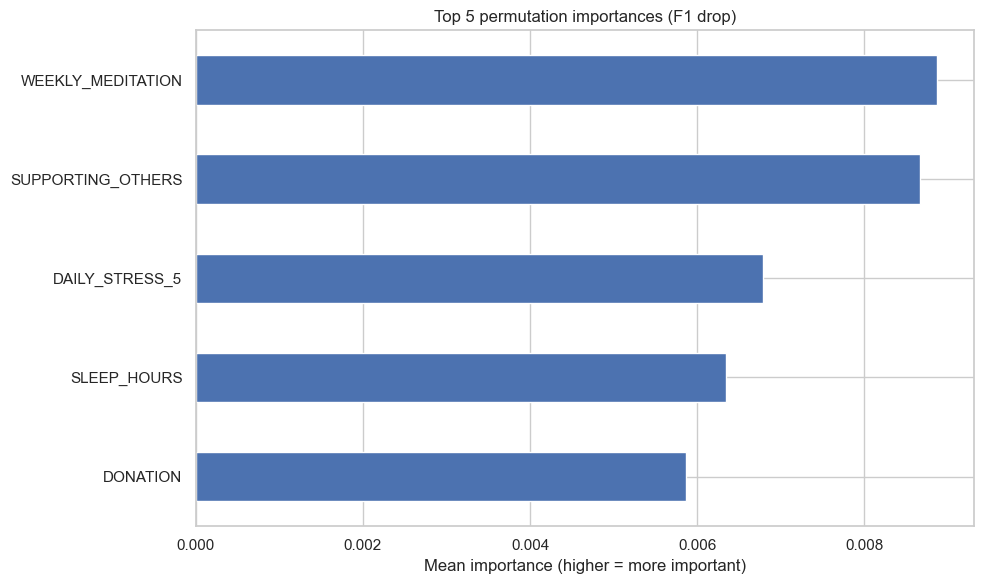

In [150]:
from sklearn.inspection import permutation_importance

feature_names = X_reduced.columns

# Permutation importance on test set
perm = permutation_importance(
    best_model,
    Xr_test,
    yr_test,
    scoring="f1",
    n_repeats=5,          # small for speed on laptop
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_imp = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=feature_names).loc[perm_imp.index]

top_n = 5
perm_top = perm_imp.head(top_n)

print("Top features (Permutation importance, scoring = F1):")
display(pd.DataFrame({
    "perm_importance_mean": perm_top,
    "perm_importance_std": perm_std.head(top_n)
}))

plt.figure(figsize=(10, 6))
perm_top.sort_values().plot(kind="barh")
plt.title(f"Top {top_n} permutation importances (F1 drop)")
plt.xlabel("Mean importance (higher = more important)")
plt.tight_layout()
plt.show()


### Error analysis

An analysis of misclassified observations was conducted using the final class-weighted XGBoost model and revealed that most errors occur in cases
where feature values lie in overlapping regions of the distributions. This confirms that misclassifications are driven primarily by limited signal in the data rather than model instability.

In particular, male observations with lifestyle patterns similar to the female majority are frequently misclassified, even by the best-performing models. This limitation reflects the inherent ambiguity of the task rather than a failure of the modelling approach.


### Ethical considerations

Gender is a sensitive attribute, and predicting it from behavioural data raises ethical concerns related to privacy, bias, and potential misuse. This project is purely exploratory and does not aim to deploy gender prediction in a real-world decision-making context. Besides ethical reasons to not use it, there are scenarios where it could be useful for example in marketing studies for digital fitness devices.

Although, the observed moderate performance highlights that lifestyle data alone should not be used to infer demographic attributes. Care was taken to analyse class imbalance and fairness, particularly by improving minority-class recall through class weighting.


### Reproducibility and code structure

All experiments are fully reproducible. A fixed random seed is used throughout the project, and all preprocessing, model training, and evaluation steps are implemented in a clear and modular way.

The notebook follows a logical structure from data loading and EDA through modelling and interpretation. Reusable functions are employed where appropriate, and intermediate results are explicitly reported to ensure transparency and ease of understanding.


### Summary and conclusions

This project demonstrates that predicting gender from wellbeing and lifestyle data is a challenging task due to substantial overlap in feature distributions and weak discriminatory signal. While advanced models such as XGBoost outperform simpler baselines, the achievable performance remains
moderate.

Feature selection, regularisation, and class weighting significantly improved model generalisation and fairness. The class-weighted XGBoost model achieved the best overall balance between precision and recall, while Logistic Regression benefited most from feature reduction.

The results highlight the importance of careful preprocessing, appropriate evaluation metrics, and ethical awareness when working with sensitive attributes. Future work could explore alternative targets, richer behavioural features, or data collected over longer periods of time to improve predictive performance.


### References

- Kaggle: Wellbeing and Lifestyle Dataset  